In [2]:

import multiprocessing

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from scipy.optimize import curve_fit
from scipy.stats import norm
from pytensor.tensor import erf

In [3]:
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "legend.fontsize": 15,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "figure.figsize": (5.8, 3.6),  # tipico per colonna singola
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})

In [4]:
# ============================================================
# ENERGY RESOLUTION
# ============================================================
def sigma_fun(E):

    A = 3.68436e1
    B = 1.72714e4

    return (
        E * pt.sqrt(A/E + B/E**2)
        / 2.355
        / 100
    )
    


In [5]:

def add_peak(ax, x, text, y_text, y_line_top=150):
    """
    ax       : axis
    x        : posizione del picco (keV)
    text     : label da scrivere
    y_text   : posizione testo
    y_line_top : altezza linea verticale
    """

    # linea verticale tratteggiata
    ax.vlines(
        x,
        0,
        y_line_top,
        ls='--',
        color='black',
        alpha=0.75
    )

    # annotazione (ruotata come nel tuo esempio)
    ax.annotate(
        text,
        xy=(x - 2, y_text),
        rotation=90,
        fontsize=11
    )

In [6]:

# ============================================================
# DATA LOADING
# ============================================================
def load_spectrum(file_path, calibration, energy_range=(0, 3000)):
    """
    Load raw spectrum and convert channels to energy.
    """

    data = pd.read_csv(file_path, header=None)
    spectrum = data[0].to_numpy(dtype=np.float64)

    channels = np.arange(len(spectrum))

    E = (
        channels * calibration["a"]
        + calibration["b"]
        + calibration["c"] * channels**2
    )

    mask = (E >= energy_range[0]) & (E <= energy_range[1])

    return E[mask], spectrum[mask]

In [7]:
# ============================================================
# HISTOGRAMMING
# ============================================================
def make_histogram(E, spectrum, bins):
    counts, edges = np.histogram(E, bins=bins, weights=spectrum)
    centers = 0.5 * (edges[1:] + edges[:-1])

    return centers, counts



In [8]:

# ============================================================
# GAUSSIAN MODEL
# ============================================================
def gaussian_plus_bg(E, mu, sigma, area, background):
    """
    Gaussian normalized to total area + flat background.
    """

    gaussian = (
        area
        / (sigma * np.sqrt(2 * np.pi))
        * np.exp(-0.5 * ((E - mu) / sigma) ** 2)
    )

    return gaussian + background


In [9]:
# ============================================================
# PEAK FITTING
# ============================================================
def fit_peak(E, counts, center, window=4, plot=True):
    """
    Fit a Gaussian peak + constant background.
    """

    mask = (E > center - window) & (E < center + window)

    E_roi = E[mask]
    counts_roi = counts[mask]

    sigma_guess = sigma_fun(center)

    p0 = [
        center,
        sigma_guess,
        np.sum(counts_roi),
        np.median(counts_roi),
    ]

    bounds = (
        [center - 1, 0.01, 0, 0],
        [center + 1, 10, np.inf, np.inf],
    )

    popt, pcov = curve_fit(
        gaussian_plus_bg,
        E_roi,
        counts_roi,
        p0=p0,
        bounds=bounds,
        #sigma=np.sqrt(counts_roi),
        maxfev=10000,
    )

    perr = np.sqrt(np.diag(pcov))

    result = {
        "mu": popt[0],
        "sigma": popt[1],
        "N": popt[2],
        "B": popt[3],
        "err_mu": perr[0],
        "err_sigma": perr[1],
        "err_N": perr[2],
        "err_B": perr[3],
    }

    if plot:
        fig, ax = plt.subplots(
            2,
            1,
            figsize=(7, 6),
            sharex=True,
            gridspec_kw={"height_ratios": [3, 1]},
        )

        E_fit = np.linspace(E_roi.min(), E_roi.max(), 400)
        model_fit = gaussian_plus_bg(E_fit, *popt)

        ax[0].step(E_roi, counts_roi, where="mid", color="black", label="Data")
        ax[0].plot(E_fit, model_fit, color="red", lw=2, label="Fit")

        ax[0].set_ylabel(f"Counts / {E_roi[1]-E_roi[0]:.2f} keV")
        ax[0].set_title(f"Peak @ {center:.2f} keV")
        ax[0].legend()
        ax[0].grid(alpha=0.3)

        residuals = counts_roi - gaussian_plus_bg(E_roi, *popt)

        ax[1].scatter(E_roi, residuals, s=15)
        ax[1].axhline(0, color="red")
        ax[1].set_xlabel("Energy [keV]")
        ax[1].set_ylabel("Residuals")
        ax[1].grid(alpha=0.3)

        plt.tight_layout()
        plt.show()

    return result


In [10]:

# ============================================================
# BUILD TOTAL DATASET
# ============================================================
def build_total_spectrum(files_config, bins):
    all_histograms = []
    total_time = 0

    for key, cfg in files_config.items():
        E, spectrum = load_spectrum(
            cfg["path"],
            cfg["calibration"],
            ENERGY_RANGE,
        )

        E_centers, counts = make_histogram(E, spectrum, bins)

        all_histograms.append(counts)
        total_time += cfg["time"]

    total_counts = np.sum(all_histograms, axis=0)

    return E_centers, total_counts, total_time

# inizio

In [11]:

FILES = {
    "50d": {
        "path": "csv-files/zro2_white&green_ 50_days.csv",
        "time": 4279386,
        "calibration": {
            "a": 0.357304,
            "b": -0.295444,
            "c": 1.352297e-9,
        },
    },
    "90d": {
        "path": "csv-files/90_days.csv",
        "time": 7550023,
        "calibration": {
            "a": 4.179423e-01,
            "b": 1.2696e-01,
            "c": 1.514025e-08,
        },
    },
}

In [12]:
ENERGY_RANGE = (0, 3000)
BIN_WIDTH = 0.42


SIGNAL = {
    "mu": 396.9,
    "roi": (340, 450),
}

SAMPLING_CONFIG = {
    "draws": 2000,
    "tune": 2000,
    "chains": 4,
    "target_accept": 0.95,
}


In [13]:
# ============================================================
# MAIN DATA PREPARATION
# ============================================================
BINS = np.arange(
    ENERGY_RANGE[0],
    ENERGY_RANGE[1] + BIN_WIDTH,
    BIN_WIDTH
)

E_tot, Ntot, t_tot = build_total_spectrum(FILES, BINS)

print(
    f"Total counts = {np.sum(Ntot):.0f} "
    f"in {t_tot / (60 * 60 * 24):.1f} days"
)


Total counts = 42047 in 136.9 days


In [14]:
peaks = [409.46,
         445.03,
         404.85,
         427.096,
         401.81,
         351.9,
         351.0592]
peaks_lines = [354.1,
               #385.1,
               391.3,
               409.8,
               416.9,
               438.9,
               445.2,
               452.2]

peaks_strange = [ 369, 379, 386, 393, 421, 433]


Text(0.5, 0, 'E (keV)')

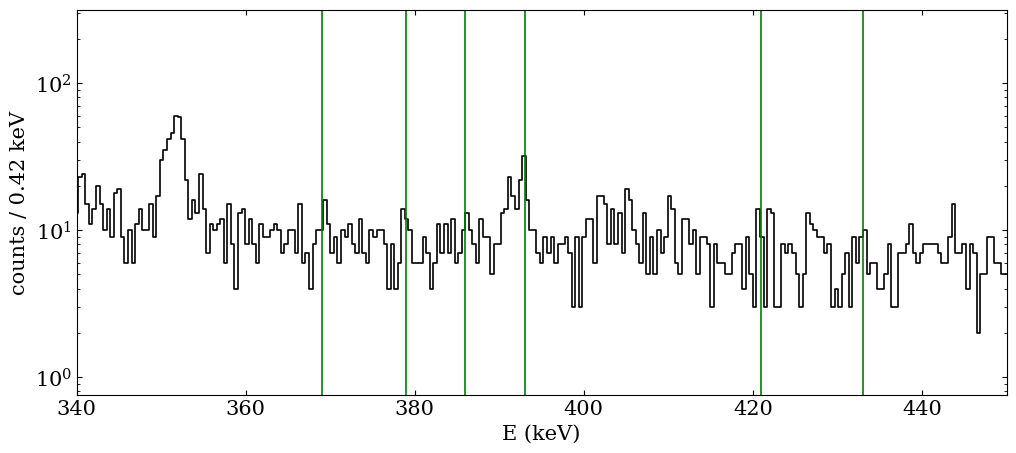

In [15]:
plt.figure(figsize=(12,5))
plt.step(E_tot, Ntot, where="mid", color="black")
#plt.axvline(SIGNAL["mu"], color = 'green', ls = '--')
'''
for p in peaks:
    plt.axvline(p,  color = 'red')
for p in peaks_lines:
    plt.axvline(p, color = 'blue')
'''
for p in peaks_strange:
    plt.axvline(p, color = 'green')
plt.yscale('log')
plt.xlim(SIGNAL["roi"][0], SIGNAL["roi"][1])
plt.ylabel("counts / 0.42 keV")
plt.xlabel("E (keV)")

In [16]:
FILES['50d']['path']

'csv-files/zro2_white&green_ 50_days.csv'

In [17]:
BACKGROUND_PEAKS = {
    "²¹¹Bi":{"E": 351.05, "N":0},
    "²¹⁴Pb": {"E": 351.92, "N": 0},
    "": {"E": 354.1, "N": 18},
    "70Ge(n,γ)": {"E": 391.3, "N" :0},
    "115In(n,γ)": {"E":385.1 , "N":0},
    "219Rn": {"E": 401.8, "N": 18},
    "²¹¹Pb": {"E": 404.85, "N": 18},
    "²²⁸Ac ": {"E": 409.462, "N": 3.55},
    "²¹¹Pb_2": {"E": 427.09, "N": 18},
    "⁴⁰K (DEP)" :{"E":438.9, "N":0},
    "p1" : {"E": 369, "N":0},
    "p2" : {"E": 379, "N":0},
    "p3" : {"E": 386, "N":0},
    "p4" : {"E": 393, "N":0},
    "p5" : {"E": 421, "N":0},
    "p6" : {"E": 433, "N":0}
}

In [18]:
roi_mask = (
    (E_tot > SIGNAL["roi"][0]) &
    (E_tot < SIGNAL["roi"][1])
)

E_roi = E_tot[roi_mask]
counts_roi = Ntot[roi_mask]

In [19]:
bin_edges = BINS
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# ============================================================
# ROI
# ============================================================
roi_mask = (
    (bin_centers >= SIGNAL["roi"][0]) &
    (bin_centers <= SIGNAL["roi"][1])
)

# Conteggi nella ROI
counts_roi = Ntot[roi_mask]

# Centri dei bin nella ROI
E_roi = bin_centers[roi_mask]

# Edge dei bin nella ROI
idx = np.where(roi_mask)[0]
bin_edges_roi = bin_edges[idx[0]:idx[-1] + 2]

# Larghezza dei bin (costante)
bin_width = bin_edges_roi[1] - bin_edges_roi[0]

In [20]:
# ============================================================
# BIN EDGES
# ============================================================

edges_low = np.asarray(
    bin_edges_roi[:-1],
    dtype=float
)

edges_high = np.asarray(
    bin_edges_roi[1:],
    dtype=float
)

E_min = edges_low[0]
E_max = edges_high[-1]

ROI_width = E_max - E_min


# ============================================================
# GAUSSIAN CDF - PyTensor safe
# ============================================================

def gaussian_cdf(x, mu, sigma):

    return 0.5 * (
        1.0
        + pt.erf(
            (x - mu)
            / (sigma * pt.sqrt(2.0))
        )
    )


# ============================================================
# EXACT GAUSSIAN BIN INTEGRAL
# ============================================================

def bin_integral(mu, sigma, low, high):

    return (
        gaussian_cdf(high, mu, sigma)
        - gaussian_cdf(low, mu, sigma)
    )


# ============================================================
# MODEL
# ============================================================

with pm.Model() as model:

    # ========================================================
    # BACKGROUND PEAKS
    # ========================================================

    A_bg = []
    mu_bg = []

    for name in BACKGROUND_PEAKS:

        fit = BACKGROUND_PEAKS[name]

        # ----------------------------------------------------
        # Peak area = expected number of counts
        # ----------------------------------------------------

        A = pm.HalfNormal(
            f"A_{name}",
            sigma=np.max(counts_roi)
        )

        # ----------------------------------------------------
        # Peak position
        # ----------------------------------------------------

        mu = pm.Normal(
            f"mu_{name}",
            mu=fit["E"],
            sigma=0.5
        )

        A_bg.append(A)
        mu_bg.append(mu)

    A_bg = pt.stack(A_bg)
    mu_bg = pt.stack(mu_bg)


    # ========================================================
    # SIGNAL
    # ========================================================

    # Signal peak area = total expected signal counts

    A_signal = pm.HalfNormal(
        "A_signal",
        sigma=np.sum(counts_roi)
    )

    # Signal peak position

    mu_signal = pm.Normal(
        "mu_signal",
        mu=SIGNAL["mu"],
        sigma=0.5
    )

    # Energy-dependent detector resolution

    sigma_signal = sigma_fun(mu_signal)


    # ========================================================
    # BACKGROUND PEAK WIDTHS
    # ========================================================
    #
    # Each background peak gets its own width evaluated
    # at its own energy.
    #
    # ========================================================

    sigma_bg = pt.stack([
        sigma_fun(mu_bg[i])
        for i in range(len(BACKGROUND_PEAKS))
    ])


    # ========================================================
    # EXPONENTIAL BACKGROUND
    # ========================================================
    #
    # Functional form:
    #
    #       f(E) ∝ exp(q * (E - E_min))
    #
    # N_exp = total number of exponential-background events
    #         inside the ROI
    #
    # q     = exponential slope
    #
    # q < 0  -> decreasing background
    # q = 0  -> flat background
    # q > 0  -> increasing background
    #
    # ========================================================

    N_exp = pm.HalfNormal(
        "N_exp",
        sigma=np.sum(counts_roi)
    )

    q = pm.Normal(
        "q",
        mu=0.0,
        sigma=1.0 / ROI_width
    )


    # ========================================================
    # EXACT NORMALIZATION OF EXPONENTIAL
    # ========================================================
    #
    # We use:
    #
    #       f(E) = exp(q * (E - E_min))
    #
    # The integral over the ROI is:
    #
    #       ∫ exp(q(E-E_min)) dE
    #
    #       = [exp(q*ROI_width) - 1] / q
    #
    # Therefore the normalized bin probability is:
    #
    #       P_i =
    #
    #       [exp(q*(high-E_min))
    #        - exp(q*(low-E_min))]
    #
    #       /
    #
    #       [exp(q*ROI_width) - 1]
    #
    #       × q
    #
    # ========================================================

    # --------------------------------------------------------
    # Numerically stable treatment of q -> 0
    # --------------------------------------------------------

    x_low = q * (edges_low - E_min)
    x_high = q * (edges_high - E_min)
    x_roi = q * ROI_width

    # --------------------------------------------------------
    # Stable exponential differences
    #
    # exp(x) - 1 = expm1(x)
    # --------------------------------------------------------

    numerator = (
        pt.exp(x_low)
        * pt.expm1(
            q * (edges_high - edges_low)
        )
    )

    denominator = pt.expm1(x_roi)

    # --------------------------------------------------------
    # q / [exp(q*ROI_width)-1]
    #
    # This approaches 1/ROI_width when q -> 0.
    #
    # We protect the denominator from numerical zero.
    # --------------------------------------------------------

    q_safe = pt.switch(
        pt.abs(q) < 1e-10,
        1e-10,
        q
    )

    exp_bin_probability = (
        numerator
        / denominator
        * q_safe
    )

    # --------------------------------------------------------
    # Explicit flat-background limit for q ≈ 0
    # --------------------------------------------------------

    exp_bin_probability = pt.switch(
        pt.abs(q) < 1e-8,
        (edges_high - edges_low) / ROI_width,
        exp_bin_probability
    )

    # --------------------------------------------------------
    # Convert probabilities into expected counts
    #
    # Sum(exp_bg_bins) = N_exp
    # --------------------------------------------------------

    exp_bg_bins = (
        N_exp
        * exp_bin_probability
    )


    # ========================================================
    # SIGNAL: EXACT BIN INTEGRALS
    # ========================================================

    sig = bin_integral(
        mu_signal,
        sigma_signal,
        edges_low,
        edges_high
    )


    # ========================================================
    # BACKGROUND PEAKS:
    # EXACT BIN INTEGRALS
    # ========================================================

    bg = pt.stack([

        bin_integral(
            mu_bg[i],
            sigma_bg[i],
            edges_low,
            edges_high
        )

        for i in range(len(BACKGROUND_PEAKS))
    ])


    # ========================================================
    # EXPECTATION PER BIN
    # ========================================================

    lambda_E = (

        # Exponential continuum
        exp_bg_bins

        +

        # Signal peak
        A_signal * sig

        +

        # Background Gaussian peaks
        pt.sum(
            A_bg[:, None] * bg,
            axis=0
        )
    )


    # ========================================================
    # POSITIVITY
    # ========================================================

    lambda_E = pt.clip(
        lambda_E,
        1e-9,
        np.inf
    )


    # ========================================================
    # POISSON LIKELIHOOD
    # ========================================================

    obs = pm.Poisson(
        "obs",
        mu=lambda_E,
        observed=counts_roi
    )


    # ========================================================
    # SAMPLING
    # ========================================================

    trace = pm.sample(
        draws=2000,
        tune=4000,
        chains=4,
        cores=min(4, multiprocessing.cpu_count()),
        target_accept=0.95,
        init="jitter+adapt_diag",
        return_inferencedata=True,
        progressbar=False,
    )

Initializing NUTS using jitter+adapt_diag...
/home/ritaferi/pymc-env/lib/python3.12/site-packages/pytensor/link/c/cmodule.py:2986: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [A_²¹¹Bi, mu_²¹¹Bi, A_²¹⁴Pb, mu_²¹⁴Pb, A_, mu_, A_70Ge(n,γ), mu_70Ge(n,γ), A_115In(n,γ), mu_115In(n,γ), A_219Rn, mu_219Rn, A_²¹¹Pb, mu_²¹¹Pb, A_²²⁸Ac , mu_²²⁸Ac , A_²¹¹Pb_2, mu_²¹¹Pb_2, A_⁴⁰K (DEP), mu

In [36]:
# ============================================================
# BIN EDGES
# ============================================================

edges_low = np.asarray(bin_edges_roi[:-1], dtype=float)

edges_high = np.asarray(bin_edges_roi[1:], dtype=float)

E_min = edges_low[0]

E_max = edges_high[-1]

ROI_width = E_max - E_min


# ============================================================
# GAUSSIAN CDF - PyTensor safe
# ============================================================

def gaussian_cdf(x, mu, sigma):

    return 0.5 * (
        1.0
        + pt.erf(
            (x - mu) / (sigma * pt.sqrt(2.0))
        )
    )


# ============================================================
# EXACT GAUSSIAN BIN INTEGRAL
# ============================================================

def bin_integral(mu, sigma, low, high):

    return (
        gaussian_cdf(high, mu, sigma)
        - gaussian_cdf(low, mu, sigma)
    )


# ============================================================
# MODEL
# ============================================================

with pm.Model() as model:

    # ========================================================
    # BACKGROUND PEAKS
    # ========================================================

    A_bg = []
    mu_bg = []

    for name in BACKGROUND_PEAKS:

        fit = BACKGROUND_PEAKS[name]

        # ----------------------------------------------------
        # Peak area = expected number of counts
        # ----------------------------------------------------

        A = pm.HalfNormal(
            f"A_{name}",
            sigma=np.max(counts_roi)
        )

        # ----------------------------------------------------
        # Peak position
        # ----------------------------------------------------

        mu = pm.Normal(
            f"mu_{name}",
            mu=fit["E"],
            sigma=0.5
        )

        A_bg.append(A)
        mu_bg.append(mu)

    A_bg = pt.stack(A_bg)

    mu_bg = pt.stack(mu_bg)


    # ========================================================
    # SIGNAL
    # ========================================================

    # Signal peak area = total expected signal counts

    A_signal = pm.HalfNormal(
        "A_signal",
        sigma=np.sum(counts_roi)
    )

    # Signal peak position

    mu_signal = pm.Normal(
        "mu_signal",
        mu=SIGNAL["mu"],
        sigma=0.5
    )

    # Energy-dependent detector resolution

    sigma_signal = sigma_fun(mu_signal)


    # ========================================================
    # BACKGROUND PEAK WIDTHS
    # ========================================================
    #
    # IMPORTANT:
    # Each background peak gets its own width evaluated
    # at its own energy.
    #

    sigma_bg = pt.stack([
        sigma_fun(mu_bg[i])
        for i in range(len(BACKGROUND_PEAKS))
    ])


    # ========================================================
    # EXPONENTIAL BACKGROUND
    #
    # N_exp = total number of exponential-background events
    #         inside the ROI
    #
    # k     = exponential slope
    #
    # PDF:
    #
    # f(E) ∝ exp[-k(E-E_min)]
    #
    # normalized over [E_min, E_max]
    # ========================================================

    N_exp = pm.HalfNormal(
        "N_exp",
        sigma=np.sum(counts_roi)
    )

    k = pm.HalfNormal(
        "k",
        sigma=1.0 / ROI_width
    )


    # ========================================================
    # EXACT NORMALIZATION OF EXPONENTIAL
    # ========================================================
    #
    # Integral of exp[-k(E-E_min)] over the ROI:
    #
    # (1 - exp[-k * ROI_width]) / k
    #
    # The normalized bin probability is therefore:
    #
    # [exp(-k(low-Emin)) - exp(-k(high-Emin))]
    #
    # /
    #
    # [1 - exp(-k*ROI_width)]
    #
    # so that:
    #
    # sum(exp_bg_bins) = N_exp
    #
    # ========================================================

    normalization = (
        1.0
        - pt.exp(-k * ROI_width)
    )

    exp_bg_bins = (
        N_exp
        *
        (
            pt.exp(
                -k * (edges_low - E_min)
            )
            -
            pt.exp(
                -k * (edges_high - E_min)
            )
        )
        / normalization
    )


    # ========================================================
    # SIGNAL: EXACT BIN INTEGRALS
    # ========================================================

    sig = bin_integral(
        mu_signal,
        sigma_signal,
        edges_low,
        edges_high
    )


    # ========================================================
    # BACKGROUND PEAKS:
    # EXACT BIN INTEGRALS
    # ========================================================

    bg = pt.stack([

        bin_integral(
            mu_bg[i],
            sigma_bg[i],
            edges_low,
            edges_high
        )

        for i in range(len(BACKGROUND_PEAKS))

    ])


    # ========================================================
    # EXPECTATION PER BIN
    # ========================================================

    lambda_E = (
        exp_bg_bins
        +
        A_signal * sig
        +
        pt.sum(
            A_bg[:, None] * bg,
            axis=0
        )
    )


    # ========================================================
    # POSITIVITY
    # ========================================================

    lambda_E = pt.clip(
        lambda_E,
        1e-9,
        np.inf
    )


    # ========================================================
    # POISSON LIKELIHOOD
    # ========================================================

    obs = pm.Poisson(
        "obs",
        mu=lambda_E,
        observed=counts_roi
    )


    # ========================================================
    # SAMPLING
    # ========================================================

    trace = pm.sample(
        draws=2000,
        tune=4000,
        chains=4,
        cores=min(4, multiprocessing.cpu_count()),
        target_accept=0.95,
        init="jitter+adapt_diag",
        return_inferencedata=True,
        progressbar=False,
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [A_²¹¹Bi, mu_²¹¹Bi, A_²¹⁴Pb, mu_²¹⁴Pb, A_, mu_, A_70Ge(n,γ), mu_70Ge(n,γ), A_115In(n,γ), mu_115In(n,γ), A_219Rn, mu_219Rn, A_²¹¹Pb, mu_²¹¹Pb, A_²²⁸Ac , mu_²²⁸Ac , A_²¹¹Pb_2, mu_²¹¹Pb_2, A_⁴⁰K (DEP), mu_⁴⁰K (DEP), A_p1, mu_p1, A_p2, mu_p2, A_p3, mu_p3, A_p4, mu_p4, A_p5, mu_p5, A_p6, mu_p6, A_signal, mu_signal, N_exp, k]
Sampling 4 chains for 4_000 tune and 2_000 draw iterations (16_000 + 8_000 draws total) took 65 seconds.


In [37]:
summary = az.summary(trace, round_to=4)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_²¹¹Bi,350.9266,0.3346,350.2461,351.5072,0.0141,0.0175,1022.2253,286.4375,1.0037
mu_²¹⁴Pb,351.9143,0.2221,351.6336,352.3022,0.0110,0.0208,1050.0285,294.5674,1.0032
mu_,354.3644,0.3376,353.7506,354.9834,0.0045,0.0069,6271.0499,4118.1561,1.0010
"mu_70Ge(n,γ)",391.3232,0.3264,390.7471,391.9723,0.0051,0.0058,4427.9799,2668.7238,1.0007
"mu_115In(n,γ)",385.1149,0.5356,384.1390,386.1264,0.0061,0.0052,7690.6946,5794.9006,1.0001
mu_219Rn,402.0339,0.2512,401.5827,402.5176,0.0028,0.0028,8279.3910,5786.6704,1.0004
mu_²¹¹Pb,405.0930,0.2550,404.6364,405.6118,0.0028,0.0031,8322.3928,5326.4811,1.0004
mu_²²⁸Ac,409.9652,0.3148,409.3812,410.5387,0.0037,0.0046,7797.6945,4957.6816,0.9999
mu_²¹¹Pb_2,427.2268,0.2953,426.6640,427.7747,0.0033,0.0037,8091.4828,5847.8874,1.0001
mu_⁴⁰K (DEP),438.9425,0.4192,438.1657,439.7390,0.0046,0.0057,8756.6639,5369.6975,1.0002


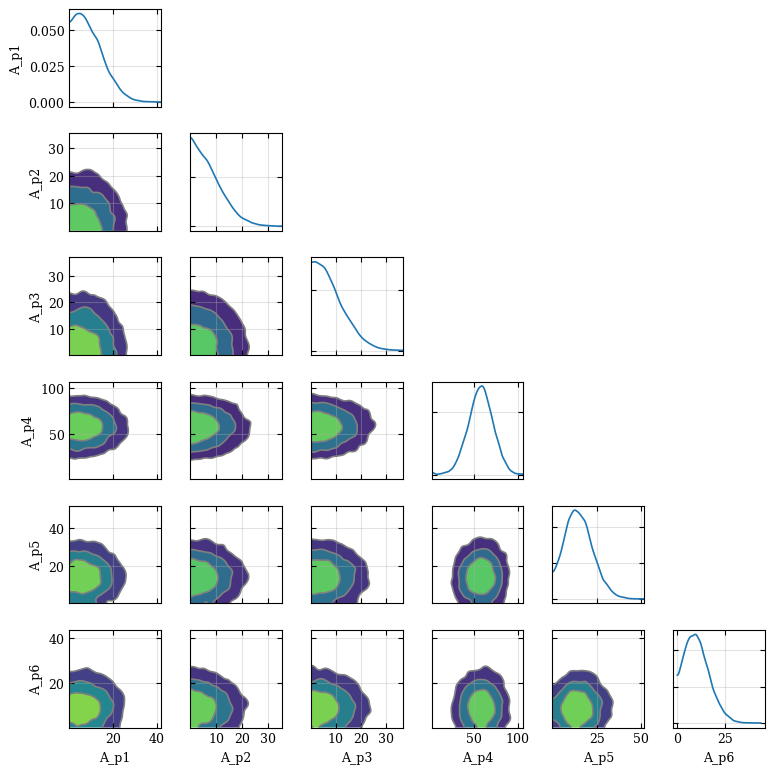

In [38]:

# ============================================================
# CORRELATION PLOTS
# ============================================================
A_vars = [v for v in trace.posterior.data_vars if v.startswith("A_")]

axes = az.plot_pair(
    trace,
    var_names=A_vars[10:-1],
    kind="kde",
    marginals=True,
    figsize=(8, 8),
    textsize=9,
)

for ax in axes.flatten():
    ax.grid(alpha=0.35)

plt.tight_layout()
plt.show()


In [39]:


# ============================================================
# POSTERIOR OF SIGNAL
# ============================================================
signal_samples = trace.posterior["A_signal"].values.flatten()

N_signal_90 = np.percentile(signal_samples, 90)
N_signal_95 = np.percentile(signal_samples, 95)

print()
print("=" * 60)
print(f"90% upper limit on signal counts : {N_signal_90:.3f}")
print(f"95% upper limit on signal counts : {N_signal_95:.3f}")
print("=" * 60)


90% upper limit on signal counts : 12.568
95% upper limit on signal counts : 15.237


(array([  1.96898215,   0.        ,   0.        ,   0.        ,
          0.        ,   1.96898215,   1.96898215,   1.96898215,
         13.78287507,  11.81389291,  11.81389291,   3.9379643 ,
         19.68982152,  15.75185722,  21.65880367,  39.37964304,
         29.53473228,  33.47269659,  43.31760735,  43.31760735,
         64.97641102,  92.54216115,  92.54216115, 102.38707191,
        143.73569711, 122.07689344, 159.48755433, 179.17737585,
        204.77414383, 220.52600105, 255.96767979, 238.24684042,
        271.719537  , 328.82001942, 301.25426929, 324.88205511,
        364.26169816, 403.6413412 , 437.11403779, 417.42421627,
        448.9279307 , 450.89691285, 488.30757374, 478.46266298,
        464.67978792, 474.52469868, 486.33859159, 543.43907401,
        496.18350235, 521.78027033, 464.67978792, 444.9899664 ,
        423.33116272, 417.42421627, 421.36218057, 326.85103726,
        356.38576955, 364.26169816, 299.28528713, 277.62648346,
        277.62648346, 196.89821522, 234.

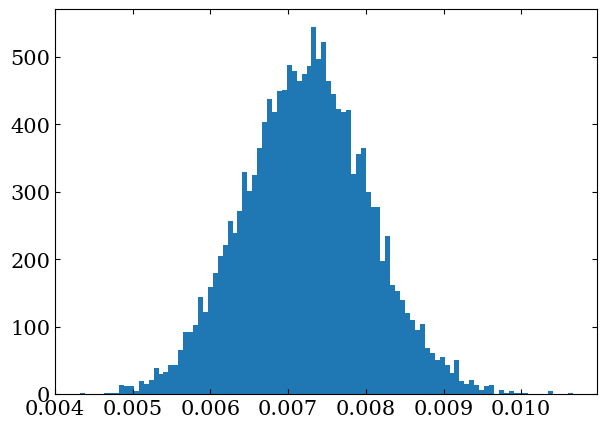

In [40]:


# ============================================================
# POSTERIOR OF SIGNAL
# ============================================================
k = trace.posterior["k"].values.flatten()
plt.figure(figsize=(7, 5))

plt.hist(k, bins=100, density=True)


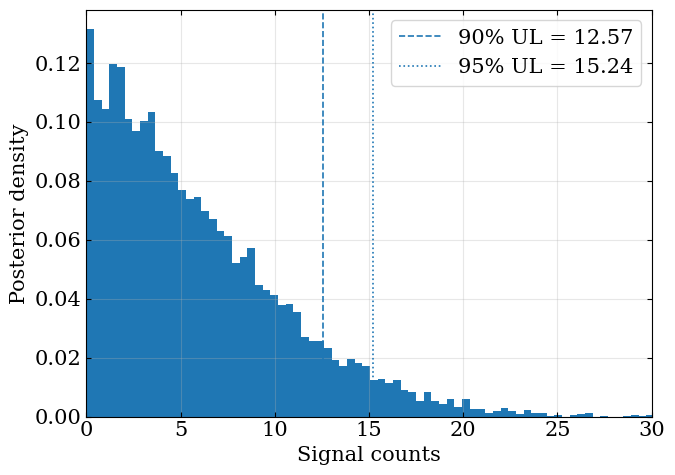

In [41]:
# ============================================================
# SIGNAL POSTERIOR PLOT
# ============================================================
plt.figure(figsize=(7, 5))

plt.hist(signal_samples, bins=80, density=True)

plt.axvline(
    N_signal_90,
    linestyle="--",
    label=f"90% UL = {N_signal_90:.2f}",
)

plt.axvline(
    N_signal_95,
    linestyle=":",
    label=f"95% UL = {N_signal_95:.2f}",
)

plt.xlabel("Signal counts")
plt.ylabel("Posterior density")
plt.grid(alpha=0.3)
plt.legend()
plt.xlim(0, 30)
plt.tight_layout()
plt.show()



In [42]:
# ============================================================
# POSTERIOR EXTRACTION
# ============================================================

background_names = list(BACKGROUND_PEAKS.keys())

idata = trace
posterior = idata.posterior


# ============================================================
# EXPONENTIAL BACKGROUND
# ============================================================

# Total number of exponential-background events
# inside the ROI

N_exp_s = (
    posterior["N_exp"]
    .values
    .reshape(-1)
)

# Exponential slope

k_s = (
    posterior["k"]
    .values
    .reshape(-1)
)


# ============================================================
# SIGNAL
# ============================================================

A_signal_s = (
    posterior["A_signal"]
    .values
    .reshape(-1)
)

mu_signal_s = (
    posterior["mu_signal"]
    .values
    .reshape(-1)
)


# ============================================================
# BACKGROUND PEAKS
# ============================================================

A_bg_s = {
    name: posterior[f"A_{name}"]
    .values
    .reshape(-1)
    for name in background_names
}

mu_bg_s = {
    name: posterior[f"mu_{name}"]
    .values
    .reshape(-1)
    for name in background_names
}

In [43]:
import numpy as np

import scipy.special


# ============================================================
# ESTRAZIONE POSTERIOR DEI PARAMETRI
# ============================================================

posterior = trace.posterior

n_posterior_samples = (
    posterior.sizes["chain"]
    *
    posterior.sizes["draw"]
)

print(
    f"Number of posterior samples: {n_posterior_samples}"
)

bin_width = edges_high - edges_low


# ============================================================
# SIGNAL PARAMETERS
# ============================================================

A_signal_s = (
    posterior["A_signal"]
    .values
    .flatten()
)

mu_signal_s = (
    posterior["mu_signal"]
    .values
    .flatten()
)


# ============================================================
# EXPONENTIAL BACKGROUND
# ============================================================

N_exp_s = (
    posterior["N_exp"]
    .values
    .flatten()
)

k_s = (
    posterior["k"]
    .values
    .flatten()
)


# ============================================================
# BACKGROUND PEAK PARAMETERS
# ============================================================

A_bg_s = []

mu_bg_s = []

for name in BACKGROUND_PEAKS:

    A_bg_s.append(
        posterior[f"A_{name}"]
        .values
        .flatten()
    )

    mu_bg_s.append(
        posterior[f"mu_{name}"]
        .values
        .flatten()
    )


A_bg_s = np.array(A_bg_s)

mu_bg_s = np.array(mu_bg_s)


print("A_bg shape:", A_bg_s.shape)

print("mu_bg shape:", mu_bg_s.shape)


# ============================================================
# STORAGE DELLE CURVE POSTERIOR
# ============================================================

lambda_total_samples = []

lambda_bkg_samples = []

n_curves = min(
    20,
    n_posterior_samples
)


# ============================================================
# LOOP SUI CAMPIONI POSTERIOR
# ============================================================

for i in range(n_curves):

    # --------------------------------------------------------
    # ENERGY DEPENDENT RESOLUTION
    # --------------------------------------------------------

    mu_sig = mu_signal_s[i]

    sigma_i = sigma_fun(mu_sig).eval()


    # --------------------------------------------------------
    # SIGNAL CONTRIBUTION
    # --------------------------------------------------------

    sig_integral = (
        0.5
        *
        (
            1.0
            +
            scipy.special.erf(
                (edges_high - mu_sig)
                /
                (sigma_i * np.sqrt(2.0))
            )
        )
        -
        0.5
        *
        (
            1.0
            +
            scipy.special.erf(
                (edges_low - mu_sig)
                /
                (sigma_i * np.sqrt(2.0))
            )
        )
    )

    signal_i = (
        A_signal_s[i]
        *
        sig_integral
    )


    # --------------------------------------------------------
    # BACKGROUND PEAKS
    # --------------------------------------------------------

    bg_i = np.zeros_like(
        edges_low,
        dtype=float
    )


    for j in range(
        len(BACKGROUND_PEAKS)
    ):

        mu_bg_i = mu_bg_s[j, i]

        bg_integral = (
            0.5
            *
            (
                1.0
                +
                scipy.special.erf(
                    (edges_high - mu_bg_i)
                    /
                    (sigma_i * np.sqrt(2.0))
                )
            )
            -
            0.5
            *
            (
                1.0
                +
                scipy.special.erf(
                    (edges_low - mu_bg_i)
                    /
                    (sigma_i * np.sqrt(2.0))
                )
            )
        )

        bg_i += (
            A_bg_s[j, i]
            *
            bg_integral
        )


    # --------------------------------------------------------
    # EXPONENTIAL BACKGROUND
    #
    # N_exp = total number of exponential-background
    #         events inside the ROI
    #
    # k = exponential slope
    #
    # B(E) ∝ exp[-k(E - E_min)]
    #
    # Exact integral over each bin
    # --------------------------------------------------------

    N_exp_i = N_exp_s[i]

    k_i = k_s[i]

    E_min = edges_low[0]

    E_max = edges_high[-1]

    ROI_width = E_max - E_min


    exp_bg_i = (
        N_exp_i
        *
        (
            np.exp(
                -k_i * (
                    edges_low - E_min
                )
            )
            -
            np.exp(
                -k_i * (
                    edges_high - E_min
                )
            )
        )
        /
        (
            1.0
            -
            np.exp(
                -k_i * ROI_width
            )
        )
    )


    # --------------------------------------------------------
    # ONLY BACKGROUND
    # --------------------------------------------------------

    bkg_model_i = (
        exp_bg_i
        +
        bg_i
    )


    # --------------------------------------------------------
    # TOTAL MODEL
    # --------------------------------------------------------

    total_model_i = (
        bkg_model_i
        +
        signal_i
    )


    # --------------------------------------------------------
    # STORAGE
    # --------------------------------------------------------

    lambda_bkg_samples.append(
        bkg_model_i
    )

    lambda_total_samples.append(
        total_model_i
    )


# ============================================================
# ARRAY FINALI
# ============================================================

lambda_bkg_samples = np.array(
    lambda_bkg_samples
)

lambda_total_samples = np.array(
    lambda_total_samples
)


print(
    "Total posterior curves:",
    lambda_total_samples.shape
)

print(
    "Background posterior curves:",
    lambda_bkg_samples.shape
)


# ============================================================
# STATISTICHE POSTERIOR
# ============================================================

# ------------------------------------------------------------
# TOTAL MODEL
# ------------------------------------------------------------

lambda_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)

lambda_total_low = np.percentile(
    lambda_total_samples,
    16,
    axis=0
)

lambda_total_high = np.percentile(
    lambda_total_samples,
    84,
    axis=0
)


# ------------------------------------------------------------
# BACKGROUND ONLY
# ------------------------------------------------------------

lambda_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)

lambda_bkg_low = np.percentile(
    lambda_bkg_samples,
    16,
    axis=0
)

lambda_bkg_high = np.percentile(
    lambda_bkg_samples,
    84,
    axis=0
)


print("Done.")

Number of posterior samples: 8000
A_bg shape: (16, 8000)
mu_bg shape: (16, 8000)
Total posterior curves: (20, 261)
Background posterior curves: (20, 261)
Done.


In [44]:
# ============================================================
# POSTERIOR SUMMARY
# ============================================================

# totale
fit_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)

fit_total_low_68 = np.percentile(
    lambda_total_samples,
    16,
    axis=0
)

fit_total_high_68 = np.percentile(
    lambda_total_samples,
    84,
    axis=0
)


fit_total_low_95 = np.percentile(
    lambda_total_samples,
    2.5,
    axis=0
)

fit_total_high_95 = np.percentile(
    lambda_total_samples,
    97.5,
    axis=0
)



# background
fit_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)

fit_bkg_low_68 = np.percentile(
    lambda_bkg_samples,
    16,
    axis=0
)

fit_bkg_high_68 = np.percentile(
    lambda_bkg_samples,
    84,
    axis=0
)


fit_bkg_low_95 = np.percentile(
    lambda_bkg_samples,
    2.5,
    axis=0
)

fit_bkg_high_95 = np.percentile(
    lambda_bkg_samples,
    97.5,
    axis=0
)

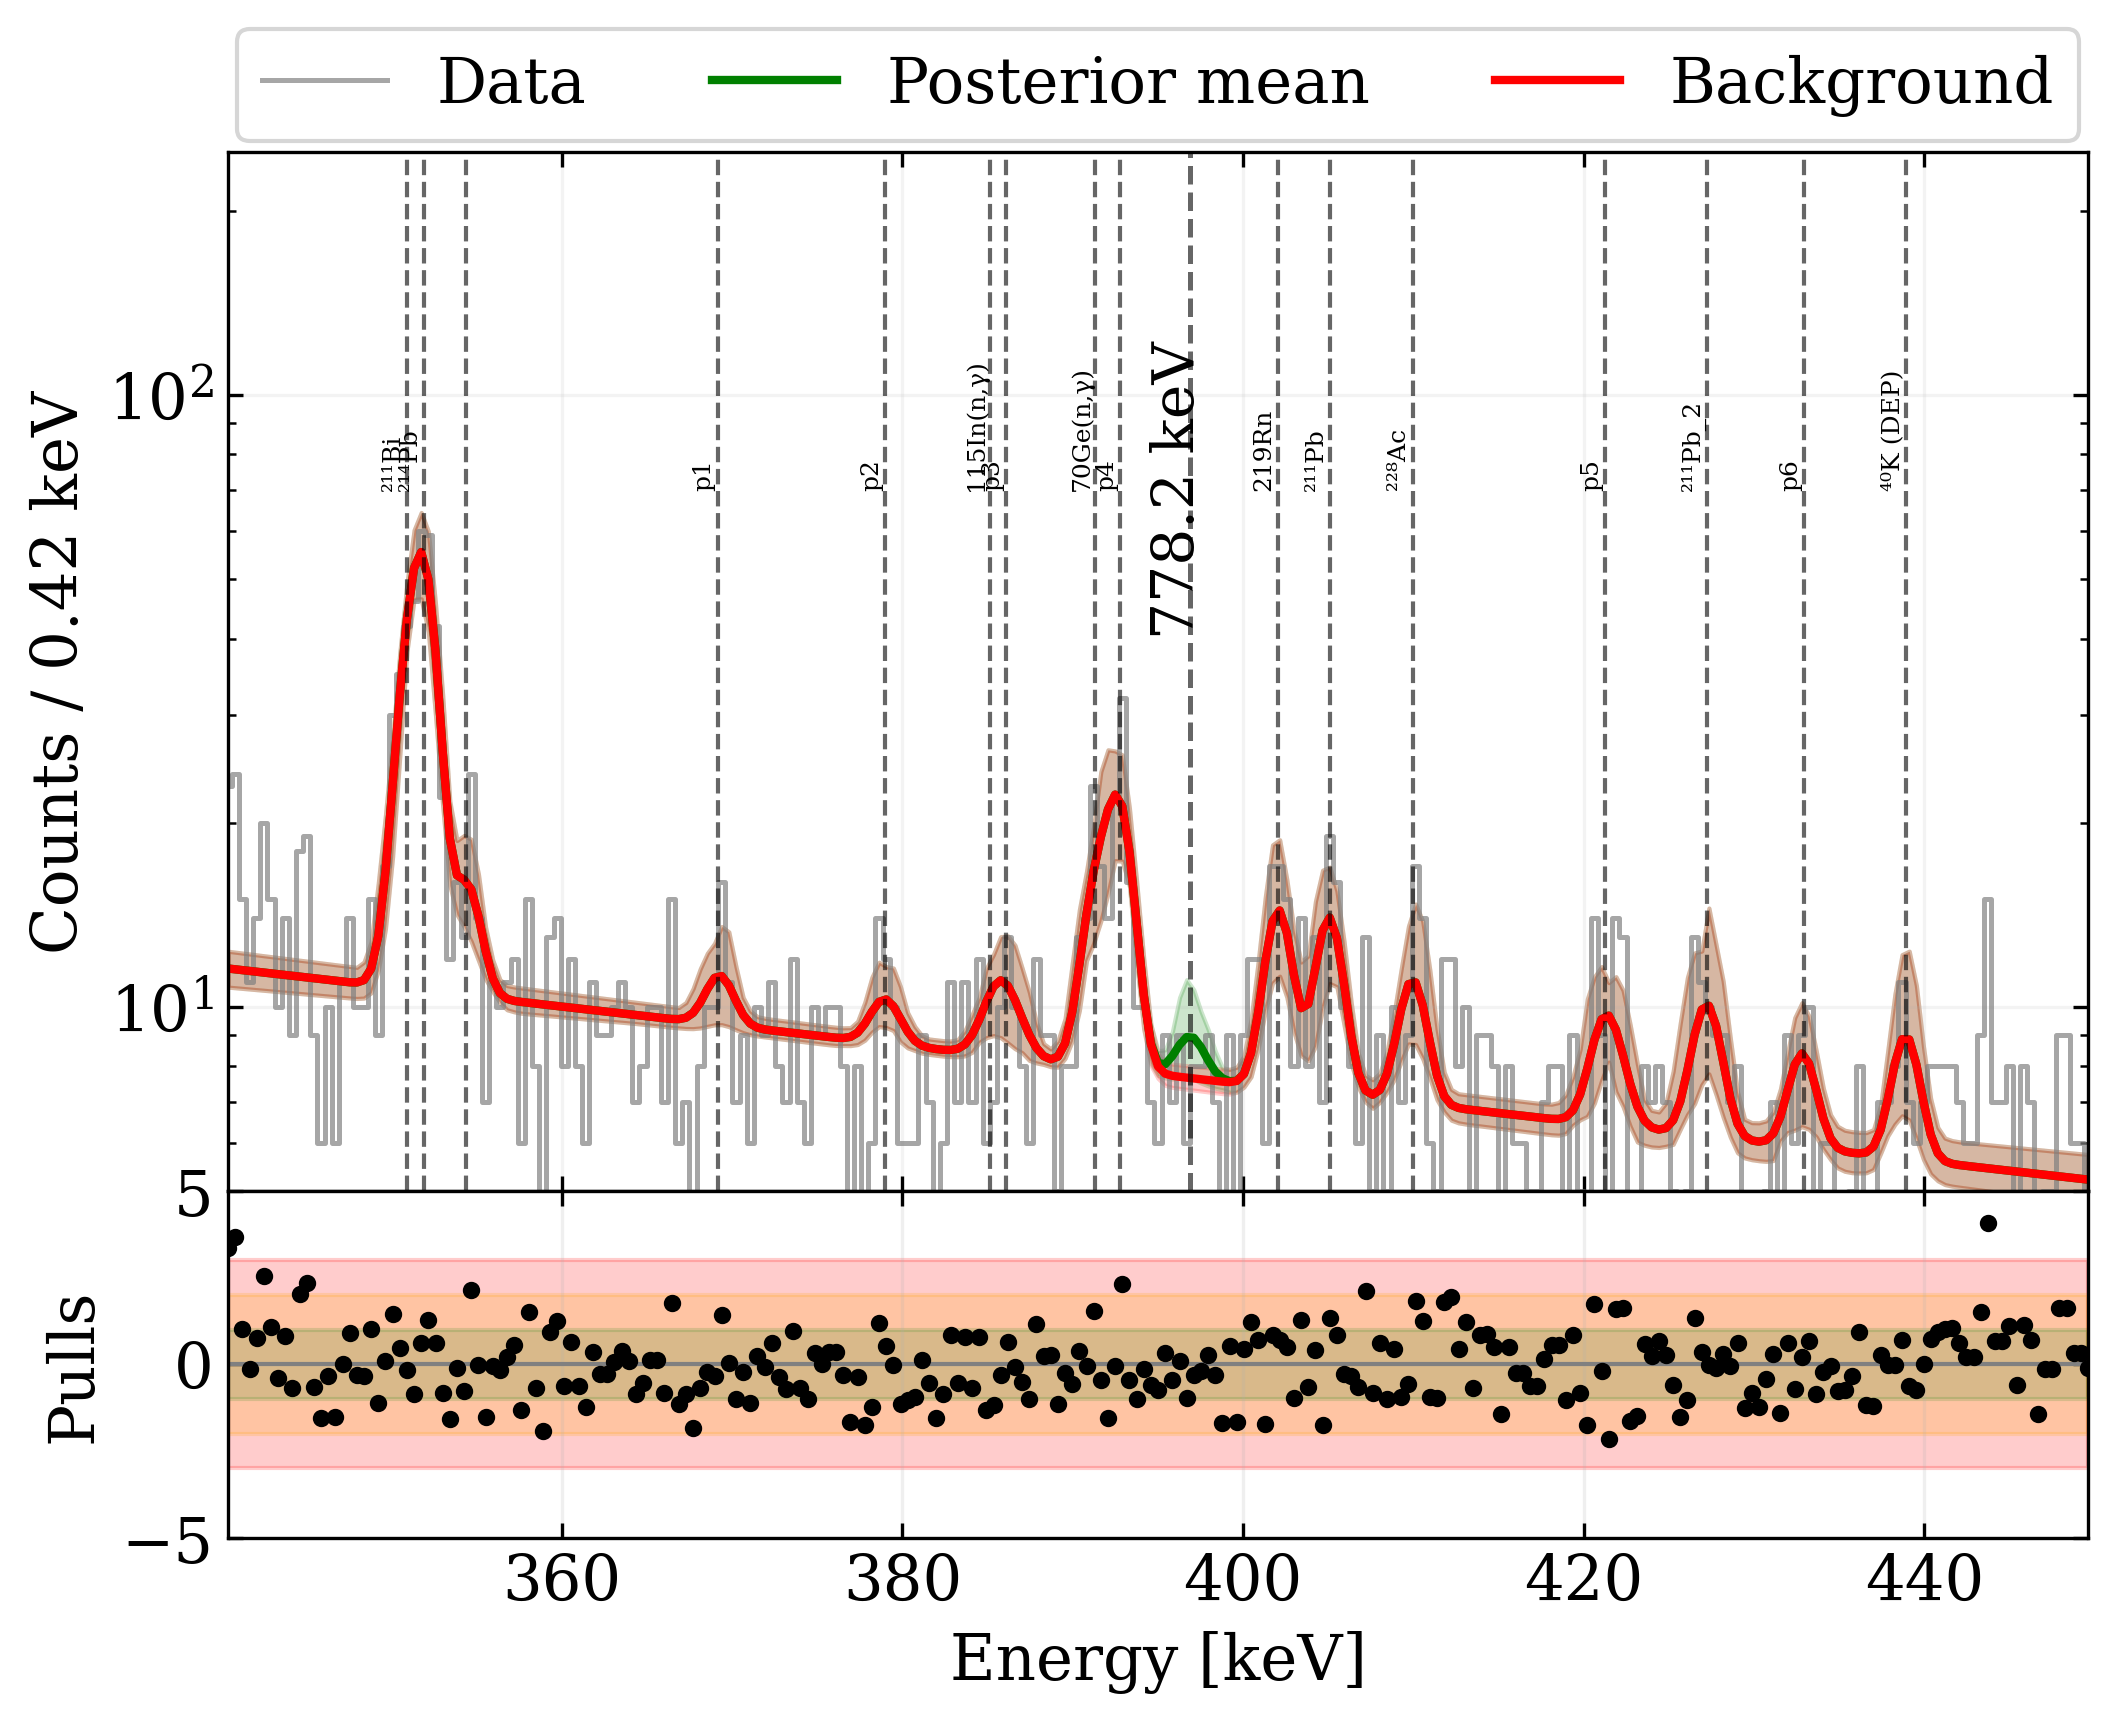

In [45]:
# ============================================================
# BAYESIAN FIT BAND
# ============================================================

# lambda_total_samples:
# (N_posterior_samples, N_bins)

lambda_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)

lambda_total_low = np.percentile(
    lambda_total_samples,
    5,
    axis=0
)

lambda_total_high = np.percentile(
    lambda_total_samples,
    95,
    axis=0
)


# background only

lambda_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)

lambda_bkg_low = np.percentile(
    lambda_bkg_samples,
    5,
    axis=0
)

lambda_bkg_high = np.percentile(
    lambda_bkg_samples,
    95,
    axis=0
)



# ============================================================
# RESIDUALS
# ============================================================

residuals = (
    counts_roi - lambda_total_mean
) / np.sqrt(lambda_total_mean + 1e-9)



# ============================================================
# BIN CENTERS
# ============================================================

E_roi = 0.5*(edges_low + edges_high)



# ============================================================
# FIGURE
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    sharex=True,
    gridspec_kw={"height_ratios": [3,1]},
    figsize=(8,6),
    dpi = 300
)



# ============================================================
# DATA
# ============================================================

ax1.step(
    E_roi,
    counts_roi,
    where="mid",
    color="grey",
    alpha=0.7,
    label="Data"
)



# ============================================================
# TOTAL BAYESIAN MODEL
# ============================================================

ax1.plot(
    E_roi,
    lambda_total_mean,
    #where="mid",
    color="green",
    lw=2,
    label="Posterior mean"
)


ax1.fill_between(
    E_roi,
    lambda_total_low,
    lambda_total_high,
    #step="mid",
    color="green",
    alpha=0.2,
    #label="68% credible interval"
)



# ============================================================
# BACKGROUND ONLY
# ============================================================

ax1.plot(
    E_roi,
    lambda_bkg_mean,
    #where="mid",
    color="red",
    lw=2,
    label="Background"
)


ax1.fill_between(
    E_roi,
    lambda_bkg_low,
    lambda_bkg_high,
    #step="mid",
    color="red",
    alpha=0.2
)


for name, peak in BACKGROUND_PEAKS.items():

    mu_samples = (
        trace.posterior[f"mu_{name}"]
        .values
        .flatten()
    )

    mu_fit = np.mean(mu_samples)

    ax1.axvline(
        mu_fit,
        color="black",
        linestyle="--",
        alpha=0.6,
        lw=1
    )

    x_text = mu_fit + 1.25 if name == "p" else mu_fit - 0.8

    ax1.text(
        x_text,
        70,
        f"{name}",
        rotation=90,
        verticalalignment="bottom",
        horizontalalignment="center",
        fontsize=6
    )



# ============================================================
# SIGNAL LINE
# ============================================================

ax1.axvline(
    SIGNAL["mu"],
    color="black",
    linestyle="--",
    alpha=0.6
)


ax1.text(
    SIGNAL["mu"]-0.7,
    40,
    "778.2 keV",
    rotation=90,
    verticalalignment="bottom",
    horizontalalignment="center",
    fontsize=14
)



# ============================================================
# AXES
# ============================================================

ax1.set_yscale("log")

ax1.set_xlim(
    E_roi.min(),
    E_roi.max()
)


ax1.set_ylim(
    5,
    250
    
)


ax1.set_ylabel(
    f"Counts / {edges_high[0]-edges_low[0]:.2f} keV"
)


ax1.grid(alpha=0.15)


ax1.legend(
    loc="lower center",
    bbox_to_anchor=(0.5,0.98),
    ncol=3
)



# ============================================================
# RESIDUALS
# ============================================================

ax2.scatter(
    E_roi,
    residuals,
    s=10,
    color="black",
    zorder = 5
)


ax2.axhspan(
    -3,
    3,
    color="red",
    alpha=0.2
)


ax2.axhspan(
    -2,
    2,
    color="orange",
    alpha=0.2
)


ax2.axhspan(
    -1,
    1,
    color="green",
    alpha=0.15
)


ax2.axhline(
    0,
    color="gray",
    lw=1,
    zorder=2
)



ax2.set_xlabel(
    "Energy [keV]"
)


ax2.set_ylabel(
    "Pulls"
)


ax2.set_ylim(
    -5,
    5
)


ax2.grid(alpha=0.2)



plt.subplots_adjust(hspace=0)

plt.show()

# half life

In [46]:
# Dati campione
m_sample = 551.3        # massa ZrO2 in grammi
Mr_sample = 123.22      # massa molare ZrO2 [g/mol]
N_A = 6.022e23          # numero di Avogadro
eff_96Zr = 0.032244    # efficienza di rivelazione
i_a_96Zr = 0.0280     # abbondanza isotopica
t_live =  t_tot/(60*60*24*365)             # 90 giorni in anni


# Numero di nuclei 96Zr nel campione
N_nuclei = (m_sample * i_a_96Zr / Mr_sample) * N_A


In [47]:
N_signal_90

np.float64(12.568350723612308)

In [48]:

percentile = 90

T_half_limit = (np.log(2) * N_nuclei * eff_96Zr * t_live) / N_signal_90
print(f"T1/2 > {T_half_limit:.2e} yrs at {percentile}%")

T1/2 > 5.03e+19 yrs at 90%


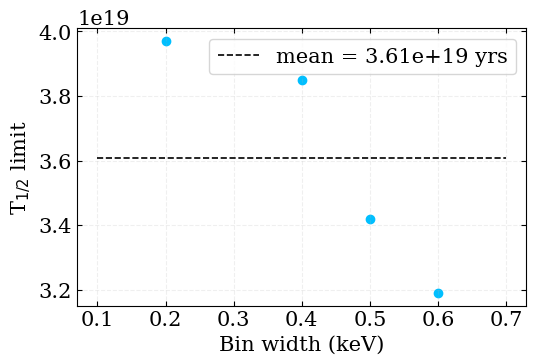

In [49]:
limit = [3.97e19, 3.85e19, 3.42e19, 3.19e+19 ]# 0.8]

bin_width = [0.2, 0.4, 0.5, 0.6]

plt.scatter(bin_width, limit, color = 'deepskyblue')
plt.hlines(np.mean(limit), min(bin_width)-0.1, max(bin_width)+0.1, color = 'black', ls = '--', label = f"mean = {np.mean(limit):.2e} yrs")
plt.ylabel(fr"T$_{{1/2}}$ limit")
plt.xlabel('Bin width (keV)')
plt.legend()
plt.grid(alpha = 0.2, ls = '--')

# activities

In [ ]:
BACKGROUND_PEAKS = {
    "²¹¹Bi":{"E": 351.05, "N":0},
    "²¹⁴Pb": {"E": 351.92, "N": 0},
    "": {"E": 354.1, "N": 18},
    "70Ge(n,γ)": {"E": 391.3, "N" :0},
    "115In(n,γ)": {"E":385.1 , "N":0},
    "219Rn": {"E": 401.8, "N": 18},
    "²¹¹Pb": {"E": 404.85, "N": 18},
    "²²⁸Ac ": {"E": 409.462, "N": 3.55},
    "²¹¹Pb_2": {"E": 427.09, "N": 18},
    "⁴⁰K (DEP)" :{"E":438.9, "N":0},
    "p1" : {"E": 369, "N":0},
    
    "p2" : {"E": 379, "N":0},
    "p3" : {"E": 386, "N":0},
    "p4" : {"E": 393, "N":0},
    "p5" : {"E": 421, "N":0},
    "p6" : {"E": 433, "N":0}
}

In [54]:
 trace.posterior.data_vars

Data variables:
    mu_²¹¹Bi       (chain, draw) float64 64kB 350.3 350.8 350.2 ... 351.0 350.9
    mu_²¹⁴Pb       (chain, draw) float64 64kB 351.8 351.9 351.9 ... 351.8 351.9
    mu_            (chain, draw) float64 64kB 354.2 354.3 354.7 ... 354.2 354.3
    mu_70Ge(n,γ)   (chain, draw) float64 64kB 391.5 391.1 391.4 ... 391.7 391.6
    mu_115In(n,γ)  (chain, draw) float64 64kB 385.0 384.4 385.6 ... 385.3 385.1
    mu_219Rn       (chain, draw) float64 64kB 402.0 402.3 401.7 ... 402.2 402.0
    mu_²¹¹Pb       (chain, draw) float64 64kB 405.2 405.1 405.1 ... 405.4 405.5
    mu_²²⁸Ac       (chain, draw) float64 64kB 409.8 409.8 410.1 ... 409.1 409.2
    mu_²¹¹Pb_2     (chain, draw) float64 64kB 426.9 427.6 426.8 ... 427.3 427.3
    mu_⁴⁰K (DEP)   (chain, draw) float64 64kB 438.6 439.0 439.3 ... 438.2 438.3
    mu_p1          (chain, draw) float64 64kB 368.5 369.5 369.1 ... 369.1 368.9
    mu_p2          (chain, draw) float64 64kB 379.2 378.4 379.6 ... 378.6 379.0
    mu_p3          (chai

In [58]:
trace.posterior.data_vars['A_²¹⁴Pb'][:-1]

samples = trace.posterior['A_²¹⁴Pb'].values.flatten()

samples

array([166.49539552, 181.16257172, 211.51666593, ..., 164.46495791,
       152.66699192, 180.22142418], shape=(8000,))

In [59]:
counts_vars = [
    v for v in trace.posterior.data_vars
    if v.startswith("A_²¹⁴Pb") 
]

counts_vars = counts_vars[:-1]
eff = np.array([
    0.0333])
br = np.array([
    0.03760])
samples = trace.posterior['A_²¹⁴Pb'].values.flatten()

activity = samples / (
        t_tot
        * m_sample_kg
        * epsilon
        * br
    )

print(
        f"{v}: "
        f"{activity.mean()*1e3:.3f} ± "
        f"{activity.std()*1e3:.3f} mBq/kg"
    )

A_219Rn: 25.890 ± 5.511 mBq/kg
